# Imports

In [1]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score


import os

# Data Loading

In [2]:
repertoire = os.getcwd()
#DATA_DIR = os.path.dirname(repertoire)

# Data loading
PCA_results = np.load(f"{repertoire}/results/resultats_PCA.npz", allow_pickle=True)
AE_results = np.load(f"{repertoire}/results/resultats_AE.npz", allow_pickle=True)

print(AE_results.files)
print(PCA_results.files)

['Z_train', 'Z_val', 'mse_train', 'mse_val', 'Z_train_profond', 'Z_val_profond', 'mse_train_profond', 'mse_val_profond', 'Z_train_profond2', 'Z_val_profond2', 'mse_train_profond2', 'mse_val_profond2', 'historique_train', 'historique_val', 'historique2_train', 'historique2_val', 'train_obs_names', 'val_obs_names']
['Z_train', 'Z_val', 'X_reconstructed_train', 'X_reconstructed_val', 'mse_train', 'mse_val', 'variance_expliquee', 'train_obs_names', 'val_obs_names']


In [3]:
X_PCA_val = PCA_results["Z_val"]
X_PCA_train = PCA_results["Z_train"]

X_AE_val = AE_results["Z_val"]
X_AE_train = AE_results["Z_train"]

X_AE_profond_val = AE_results["Z_val_profond"]
X_AE_profond_train = AE_results["Z_train_profond"]

X_AE_profond_val2=AE_results["Z_val_profond2"]

print(X_PCA_val.shape)
print(X_PCA_train.shape)

print(X_AE_val.shape)
print(X_AE_train.shape)

print(X_AE_profond_val.shape)
print(X_AE_profond_train.shape)

(3277, 64)
(13105, 64)
(3277, 64)
(13105, 64)
(3277, 64)
(13105, 64)


# Détermination du nombre de clusters - Silhouettes

PCA

Nombre optimal de clusters : 3


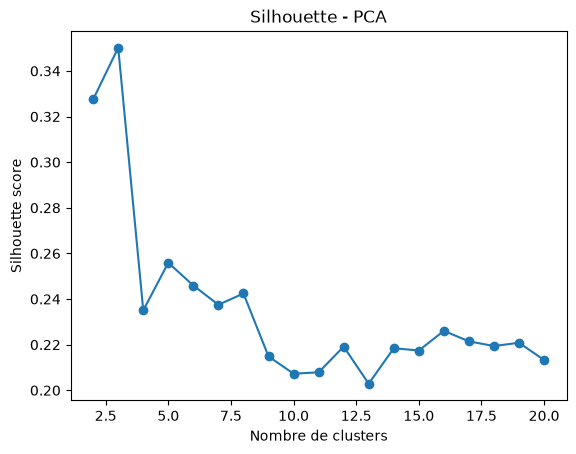

In [4]:
scores = []
K = range(2, 21)

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_PCA_train)
    scores.append(silhouette_score(X_PCA_train, labels))

best_k_PCA = list(K)[scores.index(max(scores))]

print("Nombre optimal de clusters :", best_k_PCA)

plt.plot(K, scores, marker="o")
plt.xlabel("Nombre de clusters")
plt.ylabel("Silhouette score")
plt.title("Silhouette - PCA")
plt.show()

AE

Nombre optimal de clusters : 2


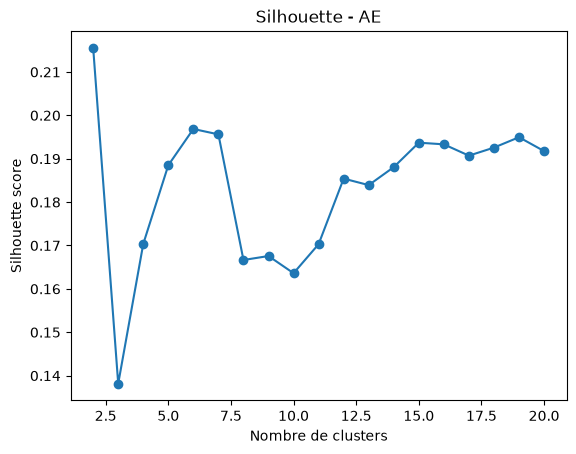

In [5]:
scores = []
K = range(2, 21)

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_AE_train)
    scores.append(silhouette_score(X_AE_train, labels))

best_k_AE = list(K)[scores.index(max(scores))]

print("Nombre optimal de clusters :", best_k_AE)

plt.plot(K, scores, marker="o")
plt.xlabel("Nombre de clusters")
plt.ylabel("Silhouette score")
plt.title("Silhouette - AE")
plt.show()

AE profond

Nombre optimal de clusters : 2


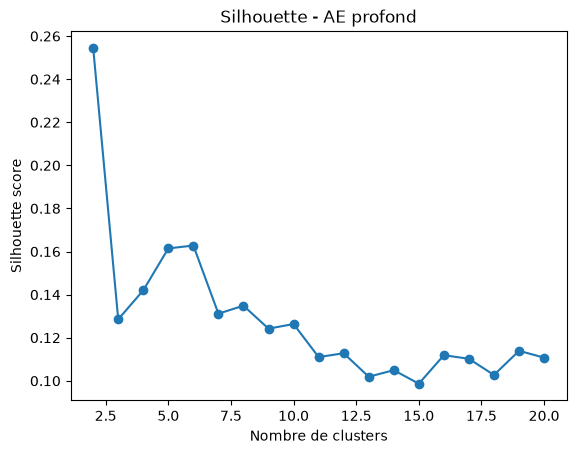

In [6]:
scores = []
K = range(2, 21)

for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_AE_profond_train)
    scores.append(silhouette_score(X_AE_profond_train, labels))

best_k_AE_profond = list(K)[scores.index(max(scores))]

print("Nombre optimal de clusters :", best_k_AE_profond)

plt.plot(K, scores, marker="o")
plt.xlabel("Nombre de clusters")
plt.ylabel("Silhouette score")
plt.title("Silhouette - AE profond")
plt.show()

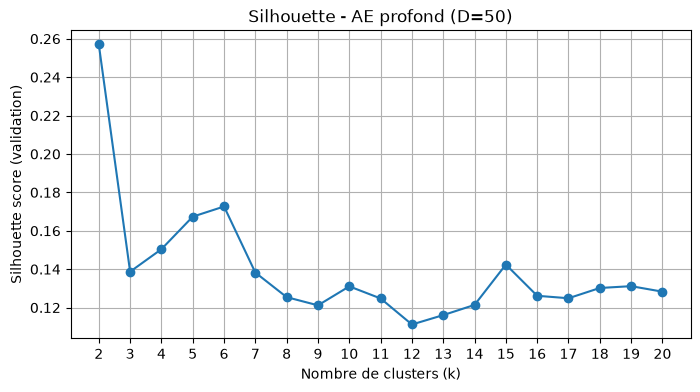

In [7]:
 # matrice latente de validation (3277 x 50)
K = range(2, 21)
scores = []

for k in K:
    model = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=20,
        random_state=42
    )
    labels = model.fit_predict(X_AE_profond_val)
    scores.append(silhouette_score(X_AE_profond_val, labels))

# Lire les pics locaux sur la courbe (au-delà de k=2..4) plutôt que le seul max global
plt.figure(figsize=(8, 4))
plt.plot(K, scores, marker="o")
plt.xticks(list(K))
plt.xlabel("Nombre de clusters (k)")
plt.ylabel("Silhouette score (validation)")
plt.title("Silhouette - AE profond (D=50)")
plt.grid(True)
plt.show()

# Kmeans

### PCA

In [8]:
kmeans_PCA = KMeans(
    n_clusters=5,#best_k_PCA,
    random_state=42,
    n_init=20
)

# Apprentissage des centroïdes
kmeans_PCA.fit(X_PCA_train)

# Attribution des clusters aux cellules du test
labels_PCA = kmeans_PCA.predict(X_PCA_val)

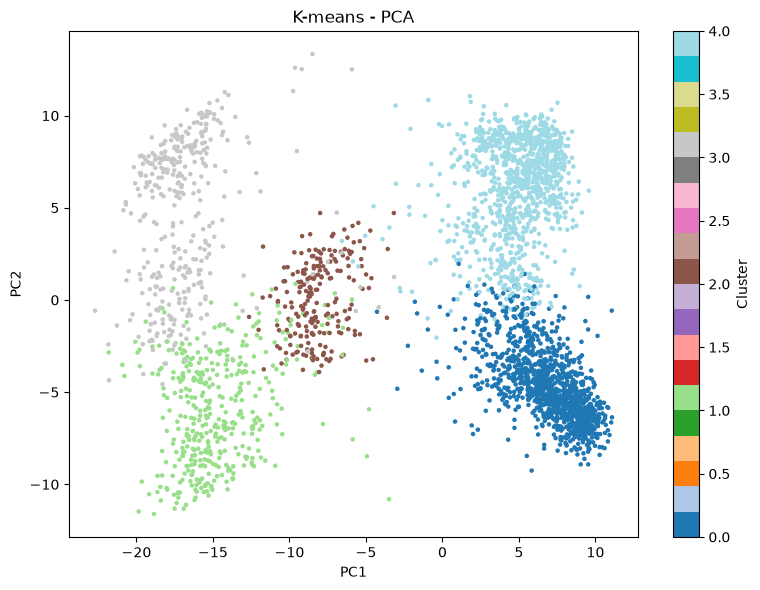

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_PCA_val[:, 0],
    X_PCA_val[:, 1],
    c=labels_PCA,
    cmap="tab20",
    s=5
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-means - PCA")
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

AE

In [10]:
kmeans_AE = KMeans(
    n_clusters=best_k_AE,
    random_state=42,
    n_init=20
)

# Apprentissage des centroïdes
kmeans_AE.fit(X_AE_train)

# Attribution des clusters aux cellules du test
labels_AE = kmeans_AE.predict(X_AE_val)

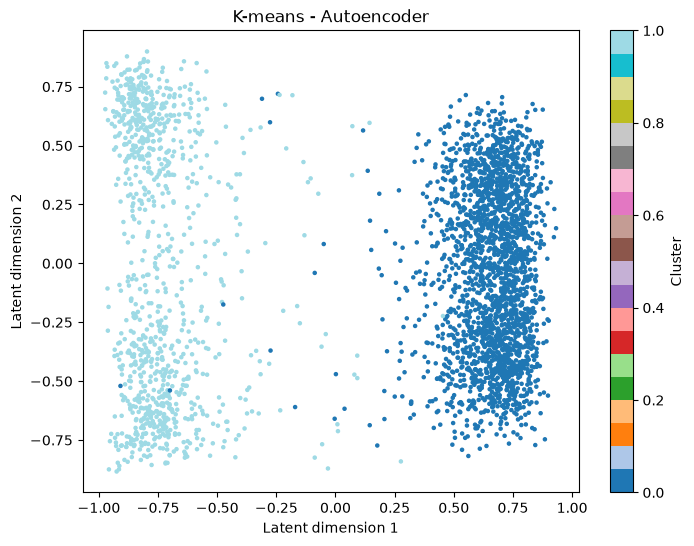

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_AE_val[:, 0],
    X_AE_val[:, 1],
    c=labels_AE,
    cmap="tab20",
    s=5
)

plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("K-means - Autoencoder")
plt.colorbar(label="Cluster")
plt.show()

AE profond

In [16]:
kmeans_AE_profond = KMeans(
    n_clusters=14,
    random_state=42,
    n_init=20
)

# Apprentissage des centroïdes
kmeans_AE_profond.fit(X_AE_profond_val)

# Attribution des clusters aux cellules du test
labels_AE_profond = kmeans_AE_profond.predict(X_AE_profond_val)

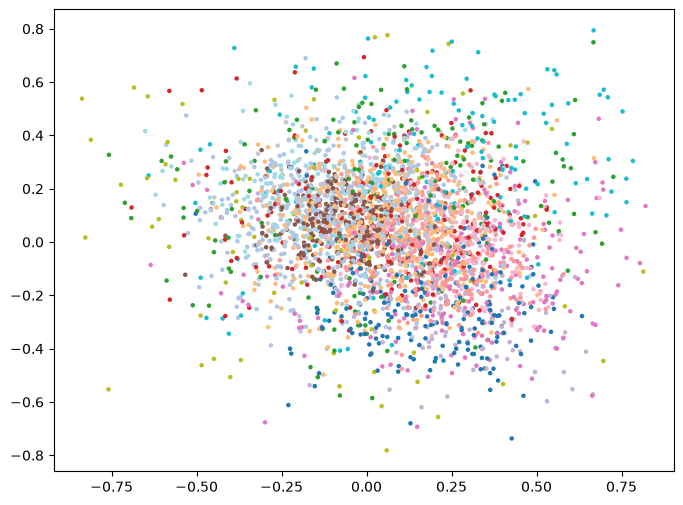

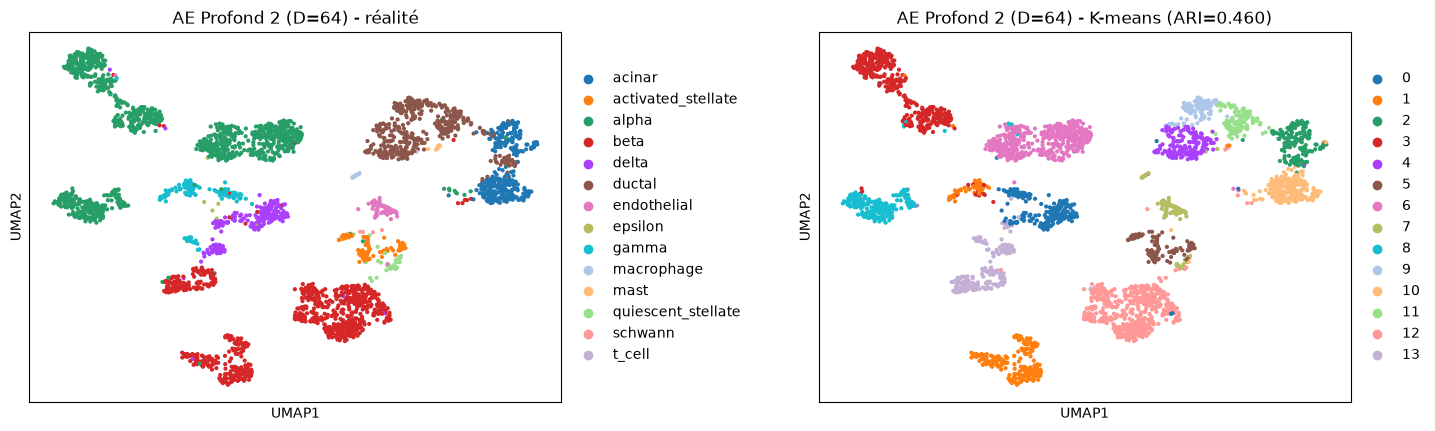

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_AE_profond_val[:, 0],
    X_AE_profond_val[:, 1],
    c=labels_AE_profond,
    cmap="tab20",
    s=5
)

"""plt.xlabel("Latent dimension 1")
plt.ylabel("Latent dimension 2")
plt.title("K-means - Autoencoder profond")
plt.colorba"""




sc.pp.neighbors(adata_rep, use_rep="X", n_neighbors=15, random_state=42)
sc.tl.umap(adata_rep, random_state=42)
sc.pl.umap(
    adata_rep,
    color=["celltype", "KMeans"],
    title=[f"{nom} - réalité", f"{nom} - K-means (ARI={ari:.3f})"],
    wspace=0.35,
    )

# ARI

### PCA

I0000 00:00:1795763916.829351 3305697 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795763917.437177 3305697 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX512_VNNI, in other operations, rebuild TensorFlow with the appropriate compiler flags.


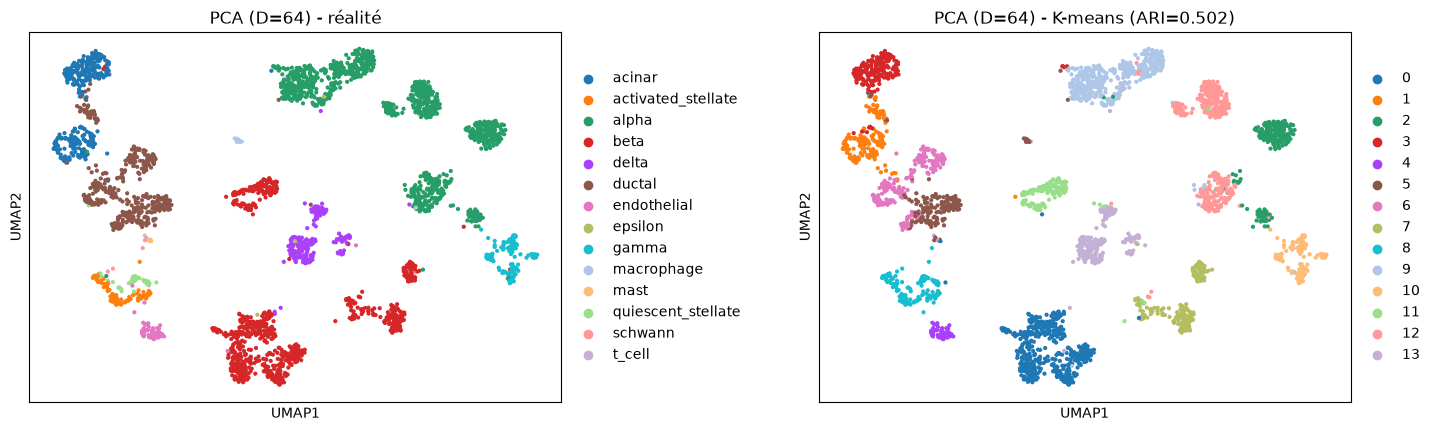

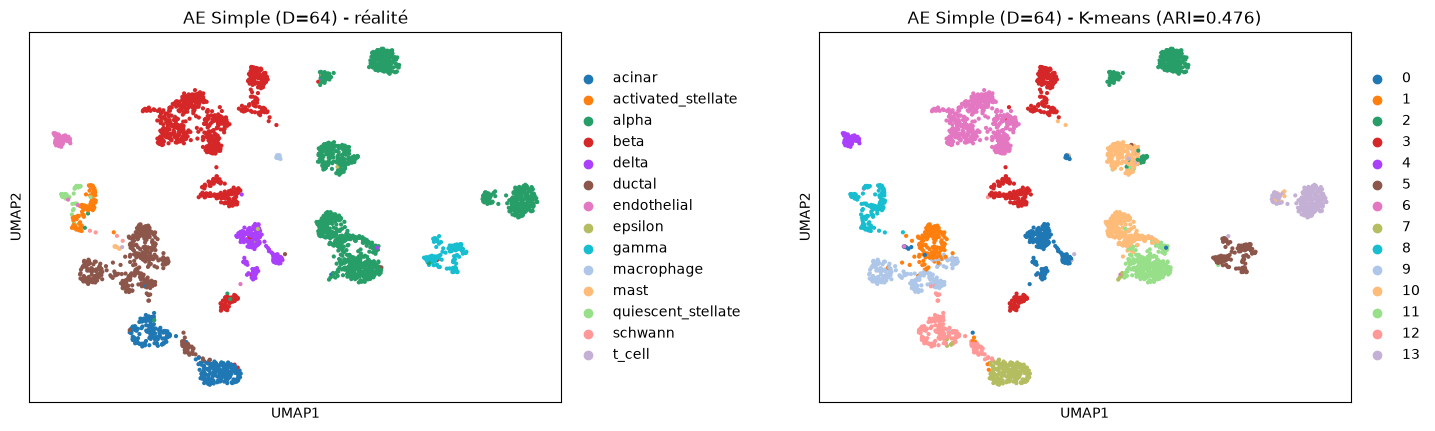

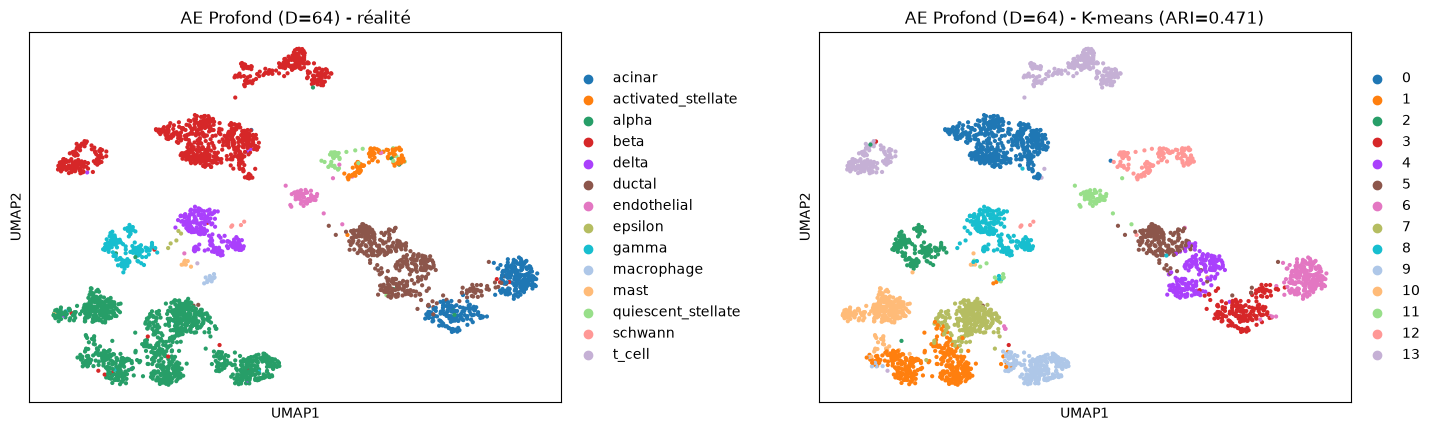

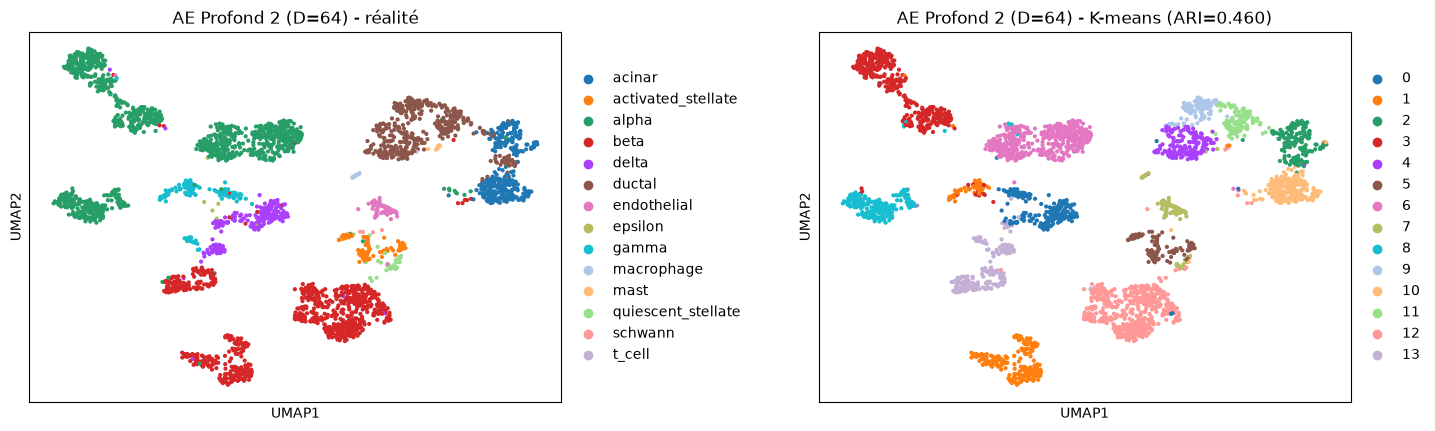

     Représentation  Clusters    ARI    NMI
         PCA (D=64)        14 0.5024 0.7499
   AE Simple (D=64)        14 0.4759 0.7437
  AE Profond (D=64)        14 0.4707 0.7391
AE Profond 2 (D=64)        14 0.4595 0.6798


In [14]:
import os
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

repertoire = os.getcwd()

# 1. Chargement des données de validation et des représentations latentes (D=50)
val = sc.read_h5ad(f"{repertoire}/data/val.h5ad")
res_ae = np.load("results/resultats_AE.npz")

y_true = val.obs["celltype"]
n_clusters = y_true.nunique()


representations = {
    "PCA (D=64)": X_PCA_val,
    "AE Simple (D=64)": X_AE_val,
    "AE Profond (D=64)": X_AE_profond_val,
    "AE Profond 2 (D=64)" : X_AE_profond_val2,
    
}

# 2. Clustering K-means sur les 64 dimensions et projection UMAP pour affichage
resultats = []

for nom, Z in representations.items():
    adata_rep = sc.AnnData(X=Z.astype(np.float32))
    adata_rep.obs = val.obs.copy()

    # K-means sur l'espace à 50 dimensions
    labels_km = KMeans(
        n_clusters=n_clusters,
        init="k-means++",
        n_init=10,
        random_state=42,
    ).fit_predict(Z)
    adata_rep.obs["KMeans"] = labels_km.astype(str)

    # Évaluation quantitative par rapport aux vrais types cellulaires
    ari = adjusted_rand_score(y_true, labels_km)
    nmi = normalized_mutual_info_score(y_true, labels_km)
    resultats.append({
        "Représentation": nom,
        "Clusters": n_clusters,
        "ARI": round(ari, 4),
        "NMI": round(nmi, 4),
    })

    # Projection UMAP des 50 dimensions vers 2D pour visualiser les clusters K-means
    sc.pp.neighbors(adata_rep, use_rep="X", n_neighbors=15, random_state=42)
    sc.tl.umap(adata_rep, random_state=42)
    sc.pl.umap(
        adata_rep,
        color=["celltype", "KMeans"],
        title=[f"{nom} - réalité", f"{nom} - K-means (ARI={ari:.3f})"],
        wspace=0.35,
    )

# 3. Tableau récapitulatif des scores K-means
df_scores = pd.DataFrame(resultats)
print(df_scores.to_string(index=False))
    
  

In [15]:
print(Z_ae_profond.shape[1])



NameError: name 'Z_ae_profond' is not defined

In [ ]:
adata_val = sc.read_h5ad("data/preprocessed.h5ad")

# Alignement des annotations sur les résultats
y_true = adata_val.obs.loc[
    PCA_results["val_obs_names"], "celltype"
]

ari_PCA = adjusted_rand_score(y_true, labels_PCA)

ari_AE = adjusted_rand_score(y_true, labels_AE)

ari_AE_profond = adjusted_rand_score(
    y_true, labels_AE_profond
)

print("ARI PCA :", ari_PCA)
print("ARI AE :", ari_AE)
print("ARI AE profond :", ari_AE_profond)

### AE

### AE Profond

# Louvain

In [ ]:
# A = kneighbors_graph(
#     X,
#     n_neighbors=15,
#     mode="connectivity",
#     include_self=False
# )

# # Symétrisation du graphe
# A = A.maximum(A.T)

# # Conversion en graphe NetworkX
# G = nx.from_scipy_sparse_array(A)

# # --------------------------------
# # 3. Application de Louvain
# # --------------------------------

# communities = nx.community.louvain_communities(
#     G,
#     weight=None,
#     resolution=1.0,
#     seed=42
# )

# # --------------------------------
# # 4. Attribution des clusters
# # --------------------------------

# labels = np.zeros(X.shape[0], dtype=int)

# for cluster_id, nodes in enumerate(communities):
#     labels[list(nodes)] = cluster_id

# print("Nombre de clusters :", len(communities))

# # --------------------------------
# # 5. Visualisation avec PCA
# # --------------------------------

# X_2D = PCA(n_components=2).fit_transform(X)

# plt.figure(figsize=(8, 6))

# plt.scatter(
#     X_2D[:, 0],
#     X_2D[:, 1],
#     c=labels,
#     cmap="viridis",
#     s=15
# )

# plt.title("Clustering Louvain")
# plt.xlabel("PC1")
# plt.ylabel("PC2")
# plt.colorbar(label="Cluster")
# plt.show()

# # Construction du graphe de voisinage
# sc.pp.neighbors(
#     adata,
#     n_neighbors=15,
#     n_pcs=30
# )

# # Clustering Louvain
# sc.tl.louvain(
#     adata,
#     resolution=1.0,
#     key_added="louvain"
# )

# # Visualisation UMAP
# sc.tl.umap(adata)

# sc.pl.umap(
#     adata,
#     color="louvain"
# )

# Leiden

In [ ]:
# import scanpy as sc
# import matplotlib.pyplot as plt

# # --------------------------------
# # 1. Prétraitement des données
# # --------------------------------

# # Normalisation
# sc.pp.normalize_total(adata, target_sum=1e4)

# # Transformation logarithmique
# sc.pp.log1p(adata)

# # Sélection des gènes variables
# sc.pp.highly_variable_genes(adata)

# adata = adata[:, adata.var.highly_variable].copy()

# # Standardisation
# sc.pp.scale(adata, max_value=10)

# # Analyse en composantes principales
# sc.tl.pca(adata, n_comps=30)

# # --------------------------------
# # 2. Construction du graphe KNN
# # --------------------------------

# sc.pp.neighbors(
#     adata,
#     n_neighbors=15,
#     n_pcs=30
# )

# # --------------------------------
# # 3. Clustering Leiden
# # --------------------------------

# sc.tl.leiden(
#     adata,
#     resolution=1.0,
#     key_added="leiden",
#     random_state=42
# )

# # --------------------------------
# # 4. Visualisation UMAP
# # --------------------------------

# sc.tl.umap(adata)

# sc.pl.umap(
#     adata,
#     color="leiden",
#     title="Clustering Leiden"
# )

# # --------------------------------
# # 5. Nombre de clusters
# # --------------------------------

# print("Nombre de clusters :",
#       adata.obs["leiden"].nunique())

# print(adata.obs["leiden"].value_counts())

# # Tester plusieurs resolutions :
# for resolution in [0.1, 0.5, 1.0, 1.5, 2.0]:

#     sc.tl.leiden(
#         adata,
#         resolution=resolution,
#         key_added=f"leiden_{resolution}",
#         random_state=42
#     )

#     n_clusters = adata.obs[
#         f"leiden_{resolution}"
#     ].nunique()

#     print(f"Resolution {resolution} : {n_clusters} clusters")